# 01 · Data Exploration & Audit

**Goal:** understand the raw UCI *Online Retail II* transactions, document every data-quality issue, and turn the findings into explicit cleaning rules.

**How this notebook is organised**

* **Part A – Descriptive audit.** Looks at all raw rows. Nothing is changed; we only measure.
* **Part B – Modeling decisions.** The cleaning rules, the daily target and the frozen train/validation/test dates, each justified by Part A.

> The final 30-day test period plays **no role** in any decision here. The cleaning rules are derived from data-quality evidence (cancellations, prices, sheet overlap, partial day), and the split dates are fixed by the calendar (last full day minus 30 days).

Run this notebook from the project root (or from `notebooks/`). It reads `data/raw/online_retail_II.xlsx` (about a minute to load).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":          # works from the project root or from notebooks/
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

from src import config, plotting
from src import data_preprocessing as dp
plotting.apply_style()
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)
GBP = FuncFormatter(plotting.gbp)
print("project folder:", ROOT.name)

project folder: retail-sales-forecasting


## Part A · Descriptive audit (all raw rows)

### A1. Shape, sheets and column names

In [2]:
sheets = dp.read_raw_sheets()
for name, frame in sheets.items():
    print(f"Sheet {name!r}: {frame.shape[0]:,} rows x {frame.shape[1]} columns")
    print("   original headers:", list(frame.columns))

raw = dp.standardize_and_combine(sheets)
print(f"\nCombined: {raw.shape[0]:,} rows x {raw.shape[1]} columns (8 data columns + source_sheet)")
del sheets
raw.head()

Sheet 'Year 2009-2010': 525,461 rows x 8 columns
   original headers: ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']
Sheet 'Year 2010-2011': 541,910 rows x 8 columns
   original headers: ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']



Combined: 1,067,371 rows x 9 columns (8 data columns + source_sheet)


,invoice_no,stock_code,description,quantity,invoice_date,unit_price,customer_id,country,source_sheet
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom,Year 2009-2010
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom,Year 2009-2010
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom,Year 2009-2010
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom,Year 2009-2010
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom,Year 2009-2010


**What we see.** The workbook has two sheets that together hold the 1,067,371 rows the UCI page advertises. The real headers are `Invoice`, `Price` and `Customer ID`; the UCI web page documents them as `InvoiceNo`, `UnitPrice` and `CustomerID`. `src/config.py` accepts both spellings and maps them to one standard set of names.

### A2. Data types and missing values

In [3]:
print(raw.dtypes.to_string())
missing = pd.DataFrame({"missing": raw.isna().sum(), "pct": raw.isna().mean() * 100})
missing

invoice_no              string
stock_code              string
description             object
quantity                 int64
invoice_date    datetime64[us]
unit_price             float64
customer_id            float64
country                    str
source_sheet               str


,missing,pct
invoice_no,0,0.00
stock_code,0,0.00
description,4382,0.41
quantity,0,0.00
invoice_date,0,0.00
unit_price,0,0.00
customer_id,243007,22.77
country,0,0.00
source_sheet,0,0.00


**What we see.** Only two columns have gaps: `description` (a tiny share) and `customer_id` (roughly one row in four). Missing customer IDs do not affect revenue, so those rows are kept; the *unique customers* metric is simply based on the rows where an ID exists. Most missing descriptions belong to zero-price adjustment rows (see A6).

### A3. Duplicates and the overlap between the two sheets

In [4]:
cols = config.STANDARD_COLUMNS
overlap_flag = dp.flag_sheet_overlap_duplicates(raw)       # raises if the two copies are NOT identical

print("Extra copies of fully identical rows (all 8 columns)   :", f"{raw.duplicated(subset=cols).sum():,}")
print("   ...repeated inside the same sheet                    :", f"{raw.duplicated(subset=cols + ['source_sheet']).sum():,}")
dups = raw[raw.duplicated(subset=cols, keep=False)]
spanning = dups.groupby(cols, dropna=False, sort=False)["source_sheet"].nunique().gt(1).sum()
print("Duplicate groups that appear in BOTH sheets              :", f"{spanning:,}")

print("\nDate range of each sheet:")
print(raw.groupby("source_sheet")["invoice_date"].agg(["min", "max", "count"]))

in_window = raw[overlap_flag]
print(f"\nRows of the later sheet inside the overlap window: {len(in_window):,}")
print("Window:", in_window["invoice_date"].min(), "->", in_window["invoice_date"].max())

after = raw[~overlap_flag]
print("Exact duplicate extra copies left after removing the overlap:", f"{after.duplicated(subset=cols).sum():,}")

Extra copies of fully identical rows (all 8 columns)   : 34,335


   ...repeated inside the same sheet                    : 12,133


Duplicate groups that appear in BOTH sheets              : 22,202

Date range of each sheet:
                               min                 max   count
source_sheet                                                  
Year 2009-2010 2009-12-01 07:45:00 2010-12-09 20:01:00  525461
Year 2010-2011 2010-12-01 08:26:00 2011-12-09 12:50:00  541910

Rows of the later sheet inside the overlap window: 22,523
Window: 2010-12-01 08:26:00 -> 2010-12-09 20:01:00


Exact duplicate extra copies left after removing the overlap: 11,812


**What we see.** The two sheets overlap for the first days of December 2010. `dp.flag_sheet_overlap_duplicates` *verified* that both sheets contain exactly the same rows in that window (same invoices, same lines, same values) before flagging the later sheet's copy. Counting both would double-count that period's revenue.

Exact duplicates that remain *inside one sheet* are a different matter: a cashier can legitimately scan the same product twice on one invoice, so we cannot tell a data-entry duplicate from a genuine repeated line. They are **kept**; their monetary weight is measured in Part B.

### A4. Date range, gaps and the last day

In [5]:
kept = raw[~overlap_flag]
day = kept["invoice_date"].dt.normalize()
calendar = pd.date_range(day.min(), day.max(), freq="D")
no_rows = calendar.difference(pd.DatetimeIndex(day.unique()))

print("First / last timestamp:", kept["invoice_date"].min(), "/", kept["invoice_date"].max())
print(f"Calendar days: {len(calendar)} | days with at least one row: {day.nunique()} | days with no rows: {len(no_rows)}")
print("\nWeekday of the days with no rows:")
print(pd.Series(no_rows.day_name()).value_counts().to_string())

non_sat = no_rows[no_rows.dayofweek != 5]
print(f"\nNo-row days that are NOT Saturdays ({len(non_sat)}):")
print(", ".join(non_sat.strftime("%Y-%m-%d")))

partial_day, evidence = dp.detect_partial_last_day(kept)
print("\nPartial-last-day check:", evidence)

First / last timestamp: 2009-12-01 07:45:00 / 2011-12-09 12:50:00
Calendar days: 739 | days with at least one row: 604 | days with no rows: 135

Weekday of the days with no rows:
Saturday     104
Monday        11
Friday         7
Sunday         6
Thursday       3
Tuesday        2
Wednesday      2

No-row days that are NOT Saturdays (31):
2009-12-24, 2009-12-25, 2009-12-27, 2009-12-28, 2009-12-29, 2009-12-30, 2009-12-31, 2010-01-01, 2010-01-03, 2010-04-02, 2010-04-04, 2010-04-05, 2010-05-03, 2010-05-31, 2010-08-30, 2010-12-24, 2010-12-26, 2010-12-27, 2010-12-28, 2010-12-29, 2010-12-30, 2010-12-31, 2011-01-02, 2011-01-03, 2011-04-22, 2011-04-24, 2011-04-25, 2011-04-29, 2011-05-02, 2011-05-30, 2011-08-29

Partial-last-day check: {'last_day': '2011-12-09', 'last_invoice_hour': 12.833, 'threshold_hour_at_percentile': 16.018, 'percentile': 0.05, 'earlier_days_with_last_invoice_at_or_before_this_hour': 0, 'earlier_days_compared': 603, 'is_partial': True}


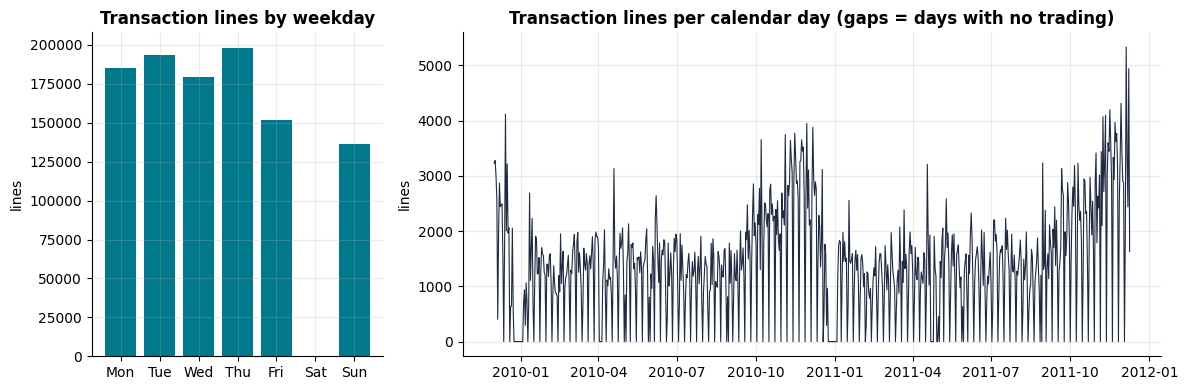

In [6]:
rows_per_day = kept.groupby(day).size().reindex(calendar, fill_value=0)
by_weekday = rows_per_day.groupby(rows_per_day.index.dayofweek).sum()

fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1, 2.4]})
axes[0].bar(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], by_weekday.values, color=plotting.COLORS["accent"])
axes[0].set_title("Transaction lines by weekday")
axes[0].set_ylabel("lines")
axes[1].plot(rows_per_day.index, rows_per_day.values, lw=0.8, color=plotting.COLORS["actual"])
axes[1].set_title("Transaction lines per calendar day (gaps = days with no trading)")
axes[1].set_ylabel("lines")
fig.tight_layout()
plotting.save_figure(fig, "fig01_daily_transaction_pattern.png")
plt.show()

**What we see.** Saturday has almost no trading at all, which is why Saturday forecasts will be close to zero. Every other no-row day is a UK public holiday (Easter, the May and August bank holidays, the one-off royal-wedding holiday of 2011-04-29) or falls in the 24 December - 3 January window. Section B and notebook 03 turn this into calendar features that are known in advance.

The final calendar day (2011-12-09) stops at 12:50, earlier than the last invoice of every previous day, so it is only partly recorded. Using it as a normal day would look like a sudden revenue crash, so it is excluded from the modeled series (Part B).

### A5. Quantity and price distributions

Quantity percentiles:
count   1,067,371.00
mean            9.94
std           172.71
min       -80,995.00
0.1%         -112.63
1%             -3.00
5%              1.00
50%             3.00
95%            30.00
99%           100.00
99.9%         500.00
max        80,995.00

Unit price percentiles:
count   1,067,371.00
mean            4.65
std           123.55
min       -53,594.36
0.1%            0.00
1%              0.21
5%              0.42
50%             2.10
95%             9.95
99%            18.00
99.9%         217.02
max        38,970.00


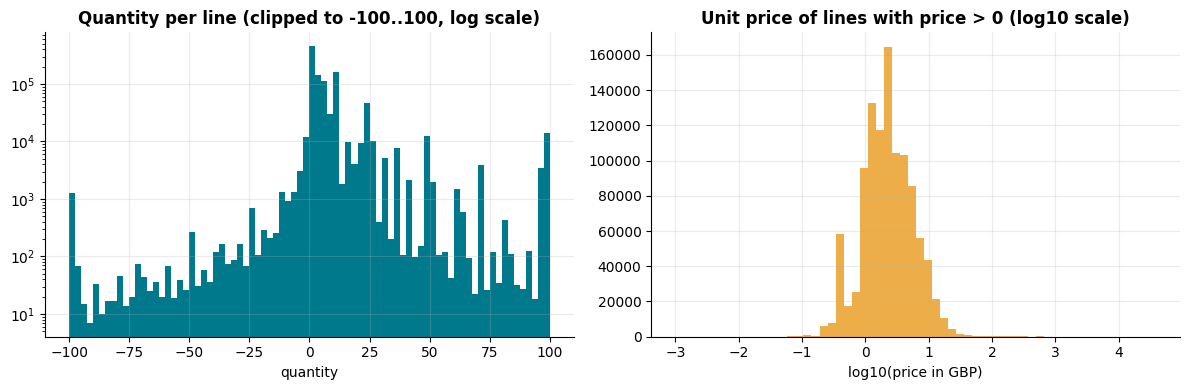

In [7]:
print("Quantity percentiles:")
print(raw["quantity"].describe(percentiles=[.001, .01, .05, .5, .95, .99, .999]).to_string())
print("\nUnit price percentiles:")
print(raw["unit_price"].describe(percentiles=[.001, .01, .05, .5, .95, .99, .999]).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(raw["quantity"].clip(-100, 100), bins=80, color=plotting.COLORS["accent"])
axes[0].set_yscale("log")
axes[0].set_title("Quantity per line (clipped to -100..100, log scale)")
axes[0].set_xlabel("quantity")
price_pos = raw.loc[raw["unit_price"] > 0, "unit_price"]
axes[1].hist(np.log10(price_pos), bins=60, color=plotting.COLORS["highlight"])
axes[1].set_title("Unit price of lines with price > 0 (log10 scale)")
axes[1].set_xlabel("log10(price in GBP)")
fig.tight_layout()
plotting.save_figure(fig, "fig02_quantity_price_distributions.png")
plt.show()

**What we see.** Quantities are heavily right-skewed: most lines are a handful of units, a few are bulk orders in the thousands, and some are negative (cancellations and adjustments). Prices are strongly right-skewed as well. Because a few extreme lines can dominate a day, we check the very largest lines in Part B before trusting the daily totals.

### A6. Cancellations, negative / zero quantities and prices

In [8]:
inv = raw["invoice_no"].str.upper()
is_c = dp.is_cancellation(raw)
qty_cat = pd.Series(np.select([raw.quantity < 0, raw.quantity == 0], ["negative", "zero"], "positive"), index=raw.index)
price_cat = pd.Series(np.select([raw.unit_price < 0, raw.unit_price == 0], ["negative", "zero"], "positive"), index=raw.index)

print(f"Rows on 'C' invoices: {is_c.sum():,} ({is_c.mean() * 100:.2f}% of raw rows)")
print("\nLeading letters of all invoice numbers:")
print(inv.str.extract(r"^([A-Z]+)")[0].value_counts().to_string())

print("\nQuantity sign by 'C' invoice flag:")
print(pd.crosstab(is_c.rename("C invoice"), qty_cat.rename("quantity")))
print("\nUnit-price sign by 'C' invoice flag:")
print(pd.crosstab(is_c.rename("C invoice"), price_cat.rename("price")))

show = ["invoice_no", "stock_code", "description", "quantity", "unit_price"]
neg_not_c = raw[(~is_c) & (raw.quantity <= 0)]
print(f"\nNon-'C' rows with quantity <= 0: {len(neg_not_c):,}; most common descriptions:")
print(neg_not_c["description"].value_counts(dropna=False).head(8).to_string())
print("\nRows with a NEGATIVE price:")
print(raw[raw.unit_price < 0][show].to_string())

Rows on 'C' invoices: 19,494 (1.83% of raw rows)

Leading letters of all invoice numbers:


0
C    19494
A        6

Quantity sign by 'C' invoice flag:
quantity   negative  positive
C invoice                    
False          3457   1044420
True          19493         1

Unit-price sign by 'C' invoice flag:


price      negative  positive  zero
C invoice                          
False             5   1041670  6202
True              0     19494     0

Non-'C' rows with quantity <= 0: 3,457; most common descriptions:
description
NaN                      2689
check                     123
damages                    84
?                          83
damaged                    78
missing                    27
sold as set on dotcom      20
Damaged                    17

Rows with a NEGATIVE price:
       invoice_no stock_code      description  quantity  unit_price
179403    A506401          B  Adjust bad debt         1  -53,594.36
276274    A516228          B  Adjust bad debt         1  -44,031.79
403472    A528059          B  Adjust bad debt         1  -38,925.87
825444    A563186          B  Adjust bad debt         1  -11,062.06
825445    A563187          B  Adjust bad debt         1  -11,062.06


**What we see.**

* Roughly 2% of rows are cancellations (invoice numbers starting with `C`); essentially all have negative quantities.
* A further group of rows has a **non-positive quantity but is *not* a `C` invoice**: stock write-offs, damages, "lost" and similar adjustments, most with a zero price and many with no description.
* A handful of rows have a **negative price** ("Adjust bad debt" entries): accounting lines, not sales.

None of these represent customers buying products, so they must not be part of the revenue target. They are *tracked separately* rather than deleted.

### A7. Suspicious / non-product stock codes

In [9]:
line_value = raw["quantity"] * raw["unit_price"]
non_std = ~raw["stock_code"].str.match(r"^\d{5}", na=False)
print(f"Rows whose stock code does not start with 5 digits: {non_std.sum():,} ({non_std.mean() * 100:.2f}%)")

codes = (raw[non_std].assign(line_value=line_value[non_std])
         .groupby("stock_code", dropna=False)
         .agg(rows=("quantity", "size"), example_description=("description", "first"),
              net_value=("line_value", "sum"))
         .sort_values("rows", ascending=False))
codes["flagged_non_product"] = codes.index.str.upper().isin(config.NON_PRODUCT_STOCK_CODES)
codes.head(25)

Rows whose stock code does not start with 5 digits: 6,093 (0.57%)


,rows,example_description,net_value,flagged_non_product
stock_code,,,,
POST,2122,POSTAGE,"112,341.00",True
DOT,1446,DOTCOM POSTAGE,"322,647.47",True
M,1421,Manual,"-82,796.32",True
C2,282,CARRIAGE,"13,386.00",True
D,177,Discount,"-13,484.54",True
S,104,SAMPLES,"-6,065.80",True
BANK CHARGES,102,Bank Charges,"-35,562.63",True
ADJUST,67,Adjustment by john on 26/01/2010 16,"6,835.24",True
AMAZONFEE,43,AMAZON FEE,"-260,763.58",True


**What we see.** Non-standard codes are a mix of two things. Codes such as postage, discounts, manual entries, bank charges, Amazon fees and test products are **not merchandise**; they are listed in `config.NON_PRODUCT_STOCK_CODES` and excluded from the target (tracked separately). Other non-standard codes (for example `DCGS…` shop items, `gift_0001_…` vouchers, `PADS`) are genuine products or sales and are **kept**.

## Part B · Modeling decisions

### B1. Apply the cleaning rules (every row gets exactly one status)

In [10]:
classified, info = dp.classify_transactions(raw)
log = dp.cleaning_log(classified)
log[["status", "rows", "line_value_gbp", "pct_of_raw_rows"]]

,status,rows,line_value_gbp,pct_of_raw_rows
0,sheet_overlap_duplicate,22523,"377,488.45",2.11
1,cancellation,19165,"-1,465,303.66",1.80
2,nonpositive_quantity,3393,0.00,0.32
3,nonpositive_price,2636,"-158,676.14",0.25
4,non_product,4489,"831,031.29",0.42
5,same_day_reversal,1250,"340,429.66",0.12
6,partial_last_day,1617,"29,644.66",0.15
7,included,1012298,"19,332,636.31",94.84


rows in log: 1,067,371 | raw rows: 1,067,371 | reconcile: True


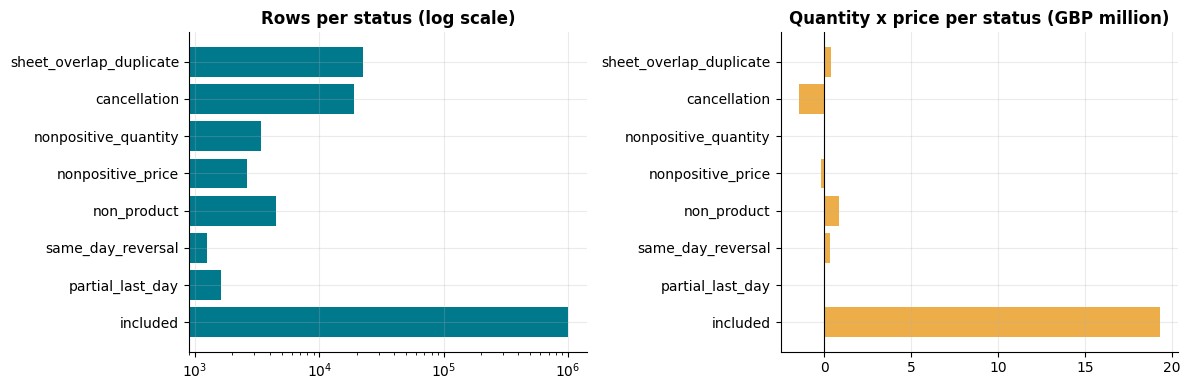

In [11]:
print("rows in log:", f"{log['rows'].sum():,}", "| raw rows:", f"{len(raw):,}", "| reconcile:", log["rows"].sum() == len(raw))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
order = log.iloc[::-1]
axes[0].barh(order["status"], order["rows"], color=plotting.COLORS["accent"])
axes[0].set_xscale("log")
axes[0].set_title("Rows per status (log scale)")
axes[1].barh(order["status"], order["line_value_gbp"] / 1e6, color=plotting.COLORS["highlight"])
axes[1].set_title("Quantity x price per status (GBP million)")
axes[1].axvline(0, color="black", lw=0.8)
fig.tight_layout()
plotting.save_figure(fig, "fig03_cleaning_waterfall.png")
plt.show()

**The cleaning rules (in priority order; a row gets the first status that applies).**

| Status | Rule | Why |
|---|---|---|
| `sheet_overlap_duplicate` | Row of the later sheet inside the verified-identical overlap window | Avoid double-counting early December 2010 |
| `cancellation` | Invoice starts with `C` | Returns/cancellations are tracked separately; not netted into the demand target |
| `nonpositive_quantity` | Not `C`, quantity <= 0 | Stock adjustments, not sales |
| `nonpositive_price` | Price <= 0 | Free items and accounting entries |
| `non_product` | Stock code in the non-product list | Postage, fees, manual lines are not product demand |
| `same_day_reversal` | Same customer cancelled the same stock code and quantity later the same day | An order correction, not demand (see B2) |
| `partial_last_day` | Rows of the incompletely recorded final day | Would look like a revenue crash |
| `included` | Everything else | The daily gross revenue target |

*Nothing is silently dropped*: every excluded row keeps its status and shows up in the tracking columns of the daily table.

### B2. Why a same-day reversal rule? The biggest order lines

In [12]:
inc = classified[classified["status"] == "included"]
rev = classified[classified["status"] == "same_day_reversal"]
show = ["invoice_no", "stock_code", "description", "quantity", "unit_price", "line_value", "invoice_date", "customer_id"]
print(f"Lines treated as same-day reversals: {len(rev):,}  (GBP {rev['line_value'].sum():,.2f})")
print("\nLargest same-day reversals:")
print(rev.nlargest(5, "line_value")[show].to_string())

# what would 2011-01-18 look like without the rule?
d = pd.Timestamp("2011-01-18")
on_day = classified[classified["invoice_date"].dt.normalize() == d]
with_rule = on_day.loc[on_day["status"] == "included", "line_value"].sum()
without_rule = on_day.loc[on_day["status"].isin(["included", "same_day_reversal"]), "line_value"].sum()
print(f"\n2011-01-18 revenue WITH the rule: GBP {with_rule:,.2f} | WITHOUT the rule: GBP {without_rule:,.2f}")

print("\nLargest INCLUDED lines (to check that no remaining line is absurd):")
print(inc.nlargest(5, "line_value")[show].to_string())

Lines treated as same-day reversals: 1,250  (GBP 340,429.66)

Largest same-day reversals:
        invoice_no stock_code                        description  quantity  unit_price  line_value        invoice_date  customer_id
1065882     581483      23843        PAPER CRAFT , LITTLE BIRDIE     80995        2.08  168,469.60 2011-12-09 09:15:00    16,446.00
587080      541431      23166     MEDIUM CERAMIC TOP STORAGE JAR     74215        1.04   77,183.60 2011-01-18 10:01:00    12,346.00
418852      529350      71477  COLOUR GLASS. STAR T-LIGHT HOLDER      1152        2.75    3,168.00 2010-10-28 09:29:00    17,450.00
267334      515281     84078A   SET/4 WHITE RETRO STORAGE CUBES         85       34.95    2,970.75 2010-07-09 13:53:00    13,734.00
900092      569385      23284      DOORMAT KEEP CALM AND COME IN       200        7.08    1,416.00 2011-10-03 16:48:00    14,031.00

2011-01-18 revenue WITH the rule: GBP 17,185.75 | WITHOUT the rule: GBP 94,394.85

Largest INCLUDED lines (to check t

**What we see.** The largest "orders" in the raw data are lines that the same customer cancelled **minutes later**, for example a 74,215-unit order worth about GBP 77k on 2011-01-18, reversed 16 minutes afterwards, and an even larger one on the (partial) final day. Left in, the January order would make that day look more than five times busier than it was and would distort every lag and rolling feature for the next 28 days.

The reversal rule is deliberately narrow (same customer, same stock code, same quantity, same day, 1-to-1 matching) and uses only same-day information, so it cannot leak future data. Its monetary effect is reported in `reports/data_audit.md` and tracked daily in `same_day_reversal_value`.

### B3. Revenue distributions after cleaning

Included line value (GBP):
count   1,012,298.00
mean           19.10
std            75.35
min             0.00
50%             9.96
90%            31.80
99%           179.00
99.9%         748.31
max        38,970.00

Daily revenue on trading days (GBP):
count       603.00
mean     32,060.76
std      16,652.06
min       3,457.11
25%      21,241.67
50%      27,974.16
75%      39,708.26
max     111,531.10

Skewness of daily revenue (trading days): 1.33


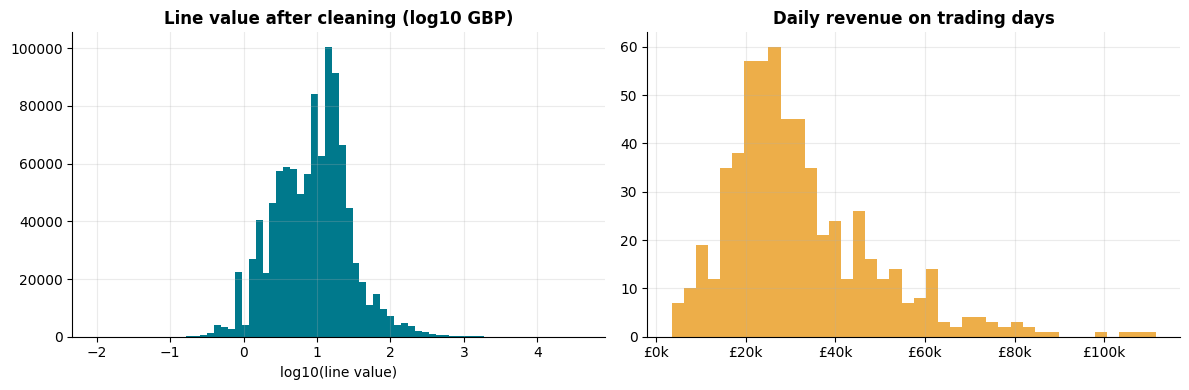

In [13]:
daily = dp.aggregate_daily(classified, info["partial_day"])
trading = daily[daily["is_trading_day"] == 1]

print("Included line value (GBP):")
print(inc["line_value"].describe(percentiles=[.5, .9, .99, .999]).to_string())
print("\nDaily revenue on trading days (GBP):")
print(trading["revenue"].describe().to_string())
print(f"\nSkewness of daily revenue (trading days): {trading['revenue'].skew():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(np.log10(inc["line_value"].clip(lower=0.01)), bins=70, color=plotting.COLORS["accent"])
axes[0].set_title("Line value after cleaning (log10 GBP)")
axes[0].set_xlabel("log10(line value)")
axes[1].hist(trading["revenue"], bins=40, color=plotting.COLORS["highlight"])
axes[1].xaxis.set_major_formatter(GBP)
axes[1].set_title("Daily revenue on trading days")
fig.tight_layout()
plotting.save_figure(fig, "fig04_revenue_distributions.png")
plt.show()

**What we see.** Individual order lines are small (most are a few pounds to a few tens of pounds) with a long tail of larger lines. Daily revenue on trading days is right-skewed: the median trading day is about GBP 28k and the busiest autumn days run to several times that. This skew is why we report both MAE (robust, in pounds) and RMSE (punishes big misses) later.

### B4. The daily target and what was set aside

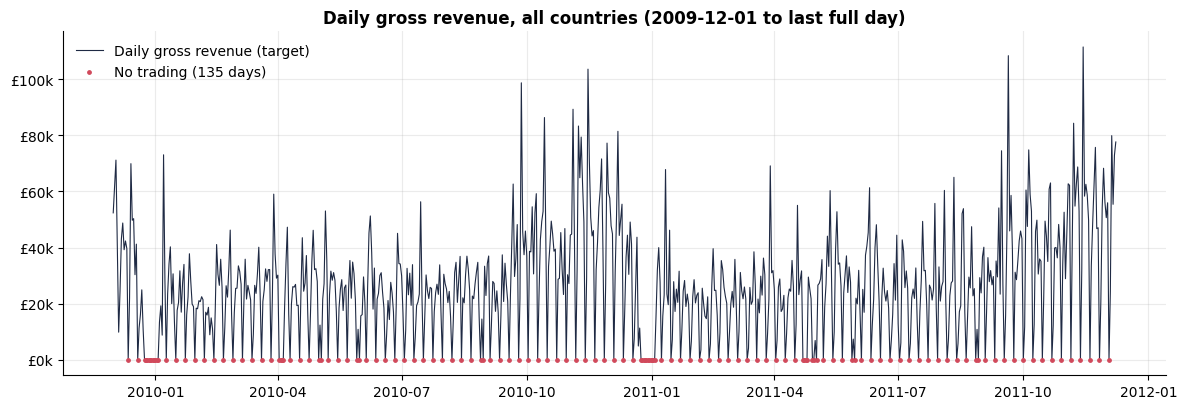

Set aside (tracked separately, not in the target):
cancel_value               GBP 1,297,261.73
non_product_value            GBP 828,206.95
same_day_reversal_value      GBP 171,960.06

Gross revenue target total: GBP 19,332,636.29
Last modeled day: 2011-12-08 | partial day excluded: 2011-12-09



Kept exact-duplicate lines inside sheets: 11,689 lines worth GBP 56,473.56 (0.29% of included revenue)


In [14]:
daily_view = daily.copy()
daily_view["date"] = pd.to_datetime(daily_view["date"])
s = daily_view.set_index("date")["revenue"]

fig, ax = plt.subplots(figsize=(12, 4.2))
ax.plot(s.index, s.values, lw=0.8, color=plotting.COLORS["actual"], label="Daily gross revenue (target)")
zero = s[s == 0]
ax.scatter(zero.index, zero.values, s=6, color=plotting.COLORS["forecast"], label=f"No trading ({len(zero)} days)", zorder=3)
ax.yaxis.set_major_formatter(GBP)
ax.set_title("Daily gross revenue, all countries (2009-12-01 to last full day)")
ax.legend(loc="upper left")
fig.tight_layout()
plotting.save_figure(fig, "fig05_daily_revenue_overview.png")
plt.show()

tracking = daily[["cancel_value", "non_product_value", "same_day_reversal_value"]].sum()
print("Set aside (tracked separately, not in the target):")
print(tracking.map("GBP {:,.2f}".format).to_string())
print(f"\nGross revenue target total: GBP {daily['revenue'].sum():,.2f}")
print("Last modeled day:", daily["date"].max().date(), "| partial day excluded:", info["partial_day"].date())

dup_mask = inc.duplicated(subset=config.STANDARD_COLUMNS)
print(f"\nKept exact-duplicate lines inside sheets: {dup_mask.sum():,} lines worth GBP {inc.loc[dup_mask, 'line_value'].sum():,.2f} "
      f"({inc.loc[dup_mask, 'line_value'].sum() / inc['line_value'].sum() * 100:.2f}% of included revenue)")

**What we see.** The target is a continuous daily series with explicit zeros for non-trading days (nothing is interpolated). The kept exact-duplicate lines are a small share of revenue, so the decision to keep them has a limited effect either way.

Cancellation value, non-product charges and reversed orders are all preserved as separate columns so the dashboard can show them.

### B5. Check: this notebook reproduces the saved processed file

In [15]:
saved = dp.load_daily_metrics()
recomputed = daily.copy()
pd.testing.assert_frame_equal(saved, recomputed, check_dtype=False, check_exact=False, atol=0.01)
print("Recomputed daily table matches data/processed/daily_metrics.csv:", saved.shape)

Recomputed daily table matches data/processed/daily_metrics.csv: (738, 15)


### B6. Frozen chronological split (decided from the calendar, before any modeling)

In [16]:
import json
print(json.dumps({k: v for k, v in config.FROZEN_SPLIT.items() if k != "validation_folds"}, indent=2))
print("\nValidation folds (expanding window):")
pd.DataFrame(config.FROZEN_SPLIT["validation_folds"])

{
  "series_start": "2009-12-01",
  "series_end": "2011-12-08",
  "pool_end": "2011-11-08",
  "test_start": "2011-11-09",
  "test_end": "2011-12-08"
}

Validation folds (expanding window):


,fold,train_end,val_start,val_end
0,1,2011-07-11,2011-07-12,2011-08-10
1,2,2011-08-10,2011-08-11,2011-09-09
2,3,2011-09-09,2011-09-10,2011-10-09
3,4,2011-10-09,2011-10-10,2011-11-08


**Decision.**

* **Series:** 2009-12-01 to 2011-12-08, the last *full* day (738 calendar days).
* **Final test set:** the last 30 days, 2011-11-09 to 2011-12-08. It is not analysed or used for tuning until the single final evaluation in notebook 04.
* **Pool:** everything before the test set (2009-12-01 to 2011-11-08). Exploration, feature decisions, validation and model selection use the pool only.
* **Validation:** four expanding-window folds of 30 days counted back from the end of the pool; each fold trains only on days *before* its validation window.

Random K-fold would let the model train on days after the ones it is scored on, which is impossible in real forecasting and would inflate every score.